# Milestone 2: Feature Engineering, Vectorization & Recommendation Engine
## Personalized TED Talks Recommendation System
**SpringBoard Internship Program / Infosys Internship**

### Objectives:
1. **Module 3: Feature Engineering & Vectorization**
   - Convert clean text (`combined_content`) into numerical TF-IDF feature vectors.
   - Tune n-gram ranges, sublinear TF scaling, and feature dimensions.
2. **Module 4: Recommendation Engine Development**
   - Compute Cosine Similarity matrix across all talks.
   - Develop content-based recommendation function `recommend(talk_title, top_n)`.
   - Evaluate recommendation relevance on benchmark TED Talks.

### Step 1: Import Required Libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Libraries successfully imported!")

Libraries successfully imported!


### Step 2: Load Preprocessed Dataset

In [2]:
df = pd.read_csv("../data/processed/ted_talks_cleaned.csv")
df["combined_content"] = df["combined_content"].fillna(df["title"])
print(f"Loaded {len(df)} preprocessed TED talks ready for vectorization.")
df[["title", "main_speaker", "tags_string", "duration_minutes"]].head(3)

Loaded 2553 preprocessed TED talks ready for vectorization.


,title,main_speaker,tags_string,duration_minutes
0,Do schools kill creativity?,Ken Robinson,children creativity culture dance education pa...,19.40
1,Averting the climate crisis,Al Gore,alternative energy cars climate change culture...,16.28
2,Simplicity sells,David Pogue,computers entertainment interface design media...,21.43


### Step 3: TF-IDF Feature Engineering (Module 3)

In [3]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

tfidf_matrix = tfidf.fit_transform(df["combined_content"])
print("TF-IDF Matrix Dimensions:", tfidf_matrix.shape)
print("Number of talks (samples):", tfidf_matrix.shape[0])
print("Number of n-gram features:", tfidf_matrix.shape[1])
print("Sample top feature names:", tfidf.get_feature_names_out()[:15])

TF-IDF Matrix Dimensions: (2553, 5000)
Number of talks (samples): 2553
Number of n-gram features: 5000
Sample top feature names: ['000' '000 dollars' '000 miles' '000 people' '000 years' '10' '10 000'
 '10 billion' '10 million' '10 minutes' '10 percent' '10 years' '100'
 '100 000' '100 percent']


### Step 4: Compute Cosine Similarity Matrix (Module 4)

In [4]:
sim_matrix = cosine_similarity(tfidf_matrix, tfidf_matrix)
print("Similarity Matrix Shape:", sim_matrix.shape)
print(f"Self-similarity diagonal verification (mean): {np.diag(sim_matrix).mean():.2f}")

Similarity Matrix Shape: (2553, 2553)
Self-similarity diagonal verification (mean): 1.00


### Step 5: Implement Recommendation Engine Function

In [5]:
title_indices = pd.Series(df.index, index=df["title"].str.lower().str.strip()).drop_duplicates()

def recommend_talks(title, top_n=5):
    query = title.lower().strip()
    if query not in title_indices:
        matches = [t for t in title_indices.index if query in t]
        if not matches:
            return f"Talk '{title}' not found."
        query = matches[0]
    
    idx = title_indices[query]
    scores = list(enumerate(sim_matrix[idx]))
    scores = sorted(scores, key=lambda x: x[1], reverse=True)[1:top_n+1]
    
    rec_indices = [i[0] for i in scores]
    rec_scores = [round(i[1], 4) for i in scores]
    
    results = df.iloc[rec_indices][["title", "main_speaker", "views", "tags_string", "url"]].copy()
    results.insert(2, "similarity_score", rec_scores)
    return results

print("Recommendation function successfully defined!")

Recommendation function successfully defined!


### Step 6: Test Case 1 — Recommending Talks for 'Do schools kill creativity?' (Ken Robinson)

In [6]:
recommend_talks("Do schools kill creativity?", top_n=5)

,title,main_speaker,similarity_score,views,tags_string,url
833,Changing education paradigms,Ken Robinson,0.2274,1854997,ted brain trust business children disease econ...,https://www.ted.com/talks/ken_robinson_changin...
2190,TED's secret to great public speaking,Chris Anderson,0.2058,2952041,brain communication language mind speech,https://www.ted.com/talks/chris_anderson_teds_...
692,Bring on the learning revolution!,Ken Robinson,0.1984,7266316,ted brain trust children creativity education ...,https://www.ted.com/talks/sir_ken_robinson_bri...
1505,How to escape education's death valley,Ken Robinson,0.1916,6657858,culture education student teaching testing,https://www.ted.com/talks/ken_robinson_how_to_...
178,"A master architect asks, Now what?",Frank Gehry,0.1720,959382,architecture business creativity culture desig...,https://www.ted.com/talks/frank_gehry_asks_the...


### Step 7: Test Case 2 — Recommending Talks for 'Your body language may shape who you are' (Amy Cuddy)

In [7]:
recommend_talks("Your body language may shape who you are", top_n=5)

,title,main_speaker,similarity_score,views,tags_string,url
1284,The game that can give you 10 extra years of life,Jane McGonigal,0.1573,6141140,aging body language cognitive science compassi...,https://www.ted.com/talks/jane_mcgonigal_the_g...
933,The hidden power of smiling,Ron Gutman,0.1546,4653286,body language culture happiness science society,https://www.ted.com/talks/ron_gutman_the_hidde...
1416,All it takes is 10 mindful minutes,Andy Puddicombe,0.1457,8033595,buddhism body language culture happiness healt...,https://www.ted.com/talks/andy_puddicombe_all_...
406,Our buggy moral code,Dan Ariely,0.1374,2725557,brain culture economics evil motivation psycho...,https://www.ted.com/talks/dan_ariely_on_our_bu...
1575,How to make stress your friend,Kelly McGonigal,0.1341,14566463,body language health psychology,https://www.ted.com/talks/kelly_mcgonigal_how_...


### Step 8: Visualizing Similarity Heatmap for Top Recommended Talks

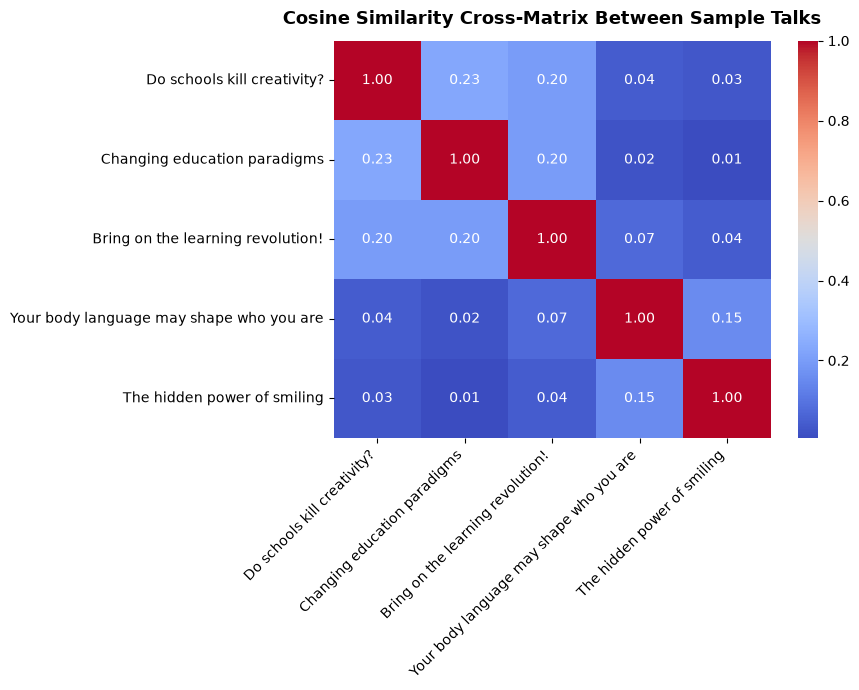

In [8]:
sample_titles = [
    "Do schools kill creativity?",
    "Changing education paradigms",
    "Bring on the learning revolution!",
    "Your body language may shape who you are",
    "The hidden power of smiling"
]

sample_indices = [title_indices[t.lower()] for t in sample_titles]
sub_sim = sim_matrix[np.ix_(sample_indices, sample_indices)]

plt.figure(figsize=(9, 7))
sns.heatmap(sub_sim, xticklabels=sample_titles, yticklabels=sample_titles, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Cosine Similarity Cross-Matrix Between Sample Talks", fontsize=13, weight="bold", pad=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()